# Inferential statistics on [Student Performance](https://archive.ics.uci.edu/dataset/320/student+performance)

In [52]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd

%matplotlib inline
sns.set_theme(style="whitegrid")

In [53]:
import os

csv = "data/student-performance.csv" if os.path.exists("data/student-performance.csv") else "student-performance.csv"
df = pd.read_csv(csv, sep=";")
print(df.shape)
df.head()

(649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [54]:
print("missing:", df.isna().sum().sum())
print("duplicates:", df.duplicated().sum())
df[["studytime", "absences", "G1", "G2", "G3"]].describe().round(1)

missing: 0


duplicates: 0


,studytime,absences,G1,G2,G3
count,649.0,649.0,649.0,649.0,649.0
mean,1.9,3.7,11.4,11.6,11.9
std,0.8,4.6,2.7,2.9,3.2
min,1.0,0.0,0.0,0.0,0.0
25%,1.0,0.0,10.0,10.0,10.0
50%,2.0,2.0,11.0,11.0,12.0
75%,2.0,6.0,13.0,13.0,14.0
max,4.0,32.0,19.0,19.0,19.0


Note: G3 is the final grade.

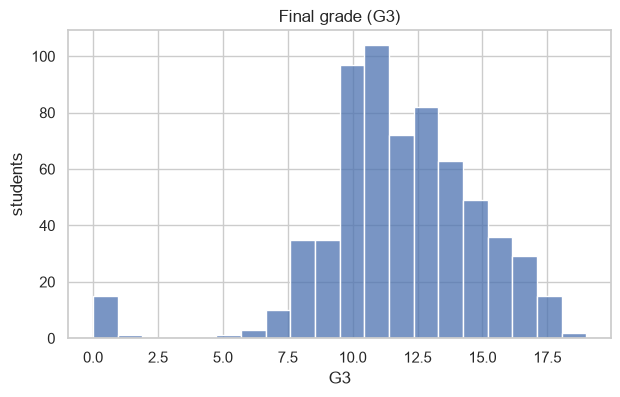

15 students got exactly 0


In [55]:
plt.figure(figsize=(7, 4))
sns.histplot(df.G3, bins=20, color="#4c72b0")
plt.title("Final grade (G3)")
plt.xlabel("G3"); plt.ylabel("students")
plt.show()

print((df.G3 == 0).sum(), "students got exactly 0")

### **Q1**. Do students who want higher education get better scores?
**Method**: Comparing two groups using a Welch **t-test**.

A Welch t-test compares the average scores of the two groups: students who want higher education and those who do not. This test is chosen because the groups might have different variances, making it more reliable than a standard t-test when equal variance cannot be assumed.


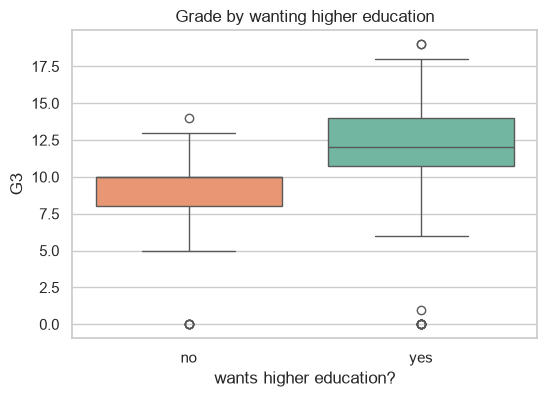

yes: 12.3 (n=580)   no: 8.8 (n=69)
gap: 3.5 points   p = 2.3e-14   d = 1.15


In [56]:
yes = df.loc[df.higher == "yes", "G3"]
no  = df.loc[df.higher == "no",  "G3"]

plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x="higher", y="G3", order=["no", "yes"],
            hue="higher", palette="Set2", legend=False)
plt.title("Grade by wanting higher education")
plt.xlabel("wants higher education?")
plt.show()

t, p = stats.ttest_ind(yes, no, equal_var=False)
d = (yes.mean() - no.mean()) / np.sqrt((yes.std(ddof=1)**2 + no.std(ddof=1)**2) / 2)
print(f"yes: {yes.mean():.1f} (n={len(yes)})   no: {no.mean():.1f} (n={len(no)})")
print(f"gap: {yes.mean()-no.mean():.1f} points   p = {p:.1e}   d = {d:.2f}")

### **Q2**. Does a mother’s level of education affect her child's grades?
**Method**: Five groups were compared using **ANOVA**. A Levene test was done first to check variances. If needed, a Tukey test followed.

Five groups are compared using ANOVA. First, a Levene's test is used to test whether the variances are equal. If the ANOVA shows a difference, a Tukey post hoc test is used to identify which groups differ.



Levene p = 0.5


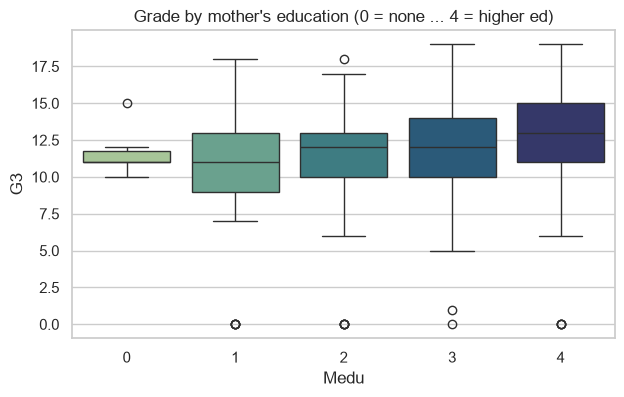

ANOVA p = 1.9e-08   eta^2 = 0.06


In [57]:
groups = [df.loc[df.Medu == k, "G3"].values for k in sorted(df.Medu.unique())]
print("Levene p =", round(stats.levene(*groups).pvalue, 2))

plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="Medu", y="G3", hue="Medu", palette="crest", legend=False)
plt.title("Grade by mother's education (0 = none ... 4 = higher ed)")
plt.xlabel("Medu")
plt.show()

F, p = stats.f_oneway(*groups)
grand = df.G3.mean()
eta2 = sum(len(g)*(g.mean()-grand)**2 for g in groups) / ((df.G3-grand)**2).sum()
print(f"ANOVA p = {p:.1e}   eta^2 = {eta2:.2f}")

In [58]:
print(pairwise_tukeyhsd(df.G3, df.Medu).summary())

Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj   lower  upper  reject
---------------------------------------------------
     0      1  -0.8695 0.9638 -4.4461 2.7071  False
     0      2  -0.0054    1.0 -3.5653 3.5545  False
     0      3   0.2542 0.9997 -3.3245 3.8329  False
     0      4   1.4019 0.8188 -2.1615 4.9653  False
     1      2   0.8641 0.0973 -0.0905 1.8186  False
     1      3   1.1237 0.0229  0.1014 2.1459   True
     1      4   2.2714    0.0  1.3039 3.2389   True
     2      3   0.2596 0.9475 -0.7027 1.2218  False
     2      4   1.4073 0.0002  0.5034 2.3111   True
     3      4   1.1477 0.0117  0.1726 2.1228   True
---------------------------------------------------


### **Q3**. Do absences affect grades?
**Method**: Measure the **correlation** between the two numbers and add a trend line.

The relationship between absences and grades is checked using correlation, and a simple line is used to show the trend.

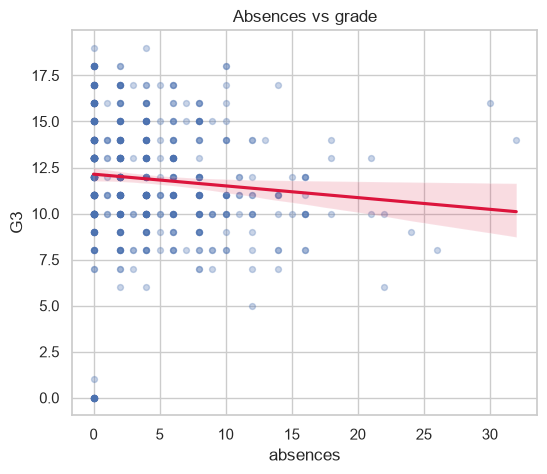

r = -0.09   p = 0.020   r^2 = 0.008


In [59]:
plt.figure(figsize=(6, 5))
sns.regplot(data=df, x="absences", y="G3",
            scatter_kws={"alpha": 0.3, "s": 18}, line_kws={"color": "crimson"})
plt.title("Absences vs grade")
plt.show()

r, p = stats.pearsonr(df.absences, df.G3)
print(f"r = {r:.2f}   p = {p:.3f}   r^2 = {r**2:.3f}")

Because the scatter plot does not show a clear linear pattern, Spearman's rank correlation uses the ranks of the data instead.

In [60]:
rho, p_s = stats.spearmanr(df.absences, df.G3)
print(f"Spearman rho = {rho:.2f}   p = {p_s:.4f}")

Spearman rho = -0.16   p = 0.0000


### **Q4**. Is there a difference between boys and girls in wanting higher education?
**Method**: The data has two categories, so a **chi-square** test is used.

A chi-square test compares boys and girls to see if there is a difference in their choices about pursuing higher education.

higher  no  yes
sex            
F       35  348
M       34  232 

smallest expected count: 28
want higher ed —  F: 91%   M: 87%
chi2 = 1.83   p = 0.18   Cramer's V = 0.05


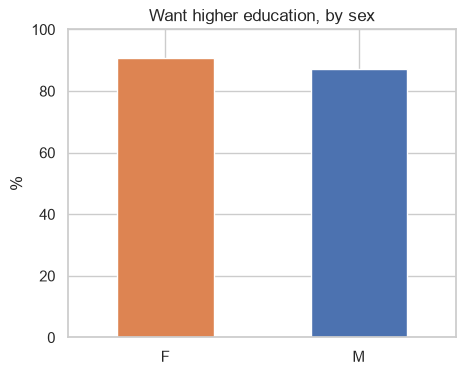

In [61]:
table = pd.crosstab(df.sex, df.higher)
chi2, p, dof, expected = stats.chi2_contingency(table)
V = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
share = table["yes"] / table.sum(axis=1) * 100

print(table, "\n")
print("smallest expected count:", round(expected.min()))
print(f"want higher ed —  F: {share['F']:.0f}%   M: {share['M']:.0f}%")
print(f"chi2 = {chi2:.2f}   p = {p:.2f}   Cramer's V = {V:.2f}")

plt.figure(figsize=(5, 4))
share.plot(kind="bar", color=["#dd8452", "#4c72b0"])
plt.title("Want higher education, by sex")
plt.ylabel("%"); plt.xlabel(""); plt.xticks(rotation=0); plt.ylim(0, 100)
plt.show()

## Questions and Answers

Q1. Do students who want higher education get better scores?

* Yes. They score about 3.5 points higher on average. The difference is significant. (t-test, d ≈ 1.15)

Q2. Does a mother’s level of education affect her child's grades?

* Yes, but only a little. It explains around 6% of the difference in grades, and the effect is mostly visible in the highest education group. (ANOVA, η² ≈ 0.06)

Q3. Do absences affect grades?

* Yes, but the effect is very small. More absences usually mean slightly lower grades, but the relationship is weak. It’s not a clear straight-line pattern. (Pearson ≈ −0.09, Spearman ≈ −0.16)

Q4. Is there a difference between boys and girls in wanting higher education?

* No real difference. Both groups are very similar (91% vs 87%). (chi-square test)

## Key Consideration

A small p-value means there is a real link, but it does not show how big the effect is. For example, both Q1 and Q3 are “significant,” but one effect is large and the other is very small. These results do not show cause and effect, since the data were only observed. The study looked at 649 students from just two schools, so the findings might not apply to other groups.